# Groupe 5 · Économie et développement
## Peut-on prédire l'espérance de vie d'un pays à partir de ses indicateurs de développement ?

**Données** : Banque mondiale, indicateurs du développement dans le monde, 2000-2022 : espérance de vie, revenu par habitant, accès à l'eau, à l'assainissement, à l'électricité, urbanisation, fécondité, dépenses de santé.

**Déroulé**
- **Partie A · Explorer les données** (étapes 1 à 9) : statistiques, valeurs manquantes, échelle logarithmique, valeurs aberrantes, corrélations, Afrique de l'Ouest
- **Partie B · Construire les modèles** (étapes 10 à 14)
- **Partie C · Analyser les résultats** (étapes 15 à 20) : le piège du découpage, résidus, pays au-dessus et en dessous des attentes, effet des valeurs aberrantes
- **Partie D · Utiliser et conclure** (étapes 21 à 23)

*Source : Banque mondiale, World Development Indicators (licence CC BY 4.0).*

# Partie A · Explorer les données

## Étape 1 · Installer et importer les outils

In [1]:
# Installe les trois bibliothèques utilisées dans ce notebook (déjà présentes dans Colab : l'installation est alors immédiate).
# Si le message « you may need to restart the kernel » apparaît, on peut l'ignorer.
%pip install -q pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np                       # calculs (ici : le logarithme)
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

## Étape 2 · Charger les données

In [3]:
import os

# Les fichiers nécessaires : ils doivent être dans le même dossier que ce notebook.
fichiers = ["indicateurs_pays.csv"]

# Dans Google Colab : si un fichier manque, une fenêtre s'ouvre pour l'envoyer depuis votre ordinateur.
if not all(os.path.exists(f) for f in fichiers):
    from google.colab import files
    files.upload()

donnees = pd.read_csv("indicateurs_pays.csv")
donnees.head()

,pays,iso3,region,annee,esperance_vie,pib_par_habitant,acces_eau,acces_assainissement,acces_electricite,population_urbaine,enfants_par_femme,depenses_sante
0,Afghanistan,AFG,"Middle East, North Africa, Afghanistan & Pakistan",2000,55.005,1617.826475,29.730966,22.298273,4.4,18.558200,7.566,NaN
1,Afghanistan,AFG,"Middle East, North Africa, Afghanistan & Pakistan",2001,55.511,1454.110782,29.762926,22.309525,9.3,18.741238,7.453,NaN
2,Afghanistan,AFG,"Middle East, North Africa, Afghanistan & Pakistan",2002,56.225,1774.308743,31.836077,23.734709,14.1,18.941248,7.320,9.443391
3,Afghanistan,AFG,"Middle East, North Africa, Afghanistan & Pakistan",2003,57.171,1815.928200,33.908629,25.160117,19.0,19.160035,7.174,8.941258
4,Afghanistan,AFG,"Middle East, North Africa, Afghanistan & Pakistan",2004,57.810,1776.918207,35.999355,26.592743,23.8,19.399359,7.018,9.808474


In [4]:
print("Lignes (un pays une année) :", len(donnees))
print("Pays :", donnees["pays"].nunique())
print("Années :", donnees["annee"].min(), "à", donnees["annee"].max())
donnees[donnees["pays"] == "Togo"].tail()

Lignes (un pays une année) : 4991
Pays : 217
Années : 2000 à 2022


,pays,iso3,region,annee,esperance_vie,pib_par_habitant,acces_eau,acces_assainissement,acces_electricite,population_urbaine,enfants_par_femme,depenses_sante
4480,Togo,TGO,Sub-Saharan Africa,2018,60.608,2787.563984,61.110617,20.606284,50.0,41.013328,4.513072,6.160737
4481,Togo,TGO,Sub-Saharan Africa,2019,61.061,2862.626612,61.576388,21.640044,52.5,41.445731,4.450408,5.912686
4482,Togo,TGO,Sub-Saharan Africa,2020,61.140,2861.297962,62.007524,22.699256,54.1,41.878153,4.386312,6.189284
4483,Togo,TGO,Sub-Saharan Africa,2021,61.337,2952.097301,62.404001,23.783621,55.7,42.310590,4.323871,5.616597
4484,Togo,TGO,Sub-Saharan Africa,2022,62.292,3086.408787,62.765613,24.892591,57.2,42.733233,4.253183,6.240941


**Les colonnes** : espérance de vie à la naissance (années) ; revenu par habitant (dollars internationaux en parité de pouvoir d'achat, PPA) ; accès à l'eau, à l'assainissement et à l'électricité (% de la population) ; population urbaine (%) ; nombre moyen d'enfants par femme ; dépenses de santé (% du PIB).

## Étape 3 · Statistiques descriptives

In [5]:
indicateurs = ["esperance_vie", "pib_par_habitant", "acces_eau", "acces_assainissement", "acces_electricite",
               "population_urbaine", "enfants_par_femme", "depenses_sante"]
donnees[indicateurs].describe().round(1)

,esperance_vie,pib_par_habitant,acces_eau,acces_assainissement,acces_electricite,population_urbaine,enfants_par_femme,depenses_sante
count,4991.0,4524.0,4804.0,4777.0,4920.0,4991.0,4991.0,4348.0
mean,70.8,23563.3,86.5,74.3,81.2,59.1,2.8,6.2
std,8.8,25238.6,17.8,29.3,29.0,24.1,1.5,2.8
min,14.7,702.9,18.8,3.0,0.8,8.0,0.7,1.2
25%,65.3,5035.5,80.6,53.0,69.4,39.0,1.7,4.1
50%,72.6,14052.4,95.1,88.6,99.0,60.4,2.3,5.6
75%,77.4,34751.1,99.3,98.0,100.0,79.0,3.7,7.9
max,86.2,174569.5,100.0,100.0,100.0,100.0,7.8,24.5


## Étape 4 · Les valeurs manquantes

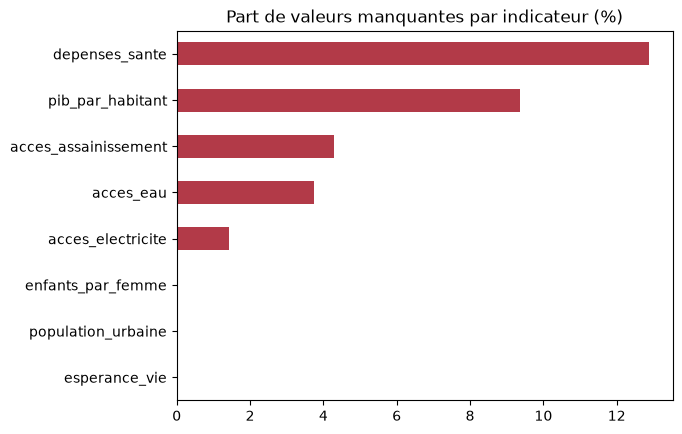

pays
Kosovo                       100
Channel Islands               92
American Samoa                69
South Sudan                   69
Turks and Caicos Islands      62
Korea, Dem. People's Rep.     57
Isle of Man                   55
British Virgin Islands        52
dtype: int64

In [6]:
part_manquante = (donnees[indicateurs].isna().mean() * 100).sort_values()
part_manquante.plot(kind="barh", color="#B23A48")
plt.title("Part de valeurs manquantes par indicateur (%)")
plt.show()

# Quels pays ont le plus de trous ?
trous_par_pays = donnees[indicateurs].isna().sum(axis=1).groupby(donnees["pays"]).sum().sort_values(ascending=False)
trous_par_pays.head(8)

Les valeurs manquent surtout pour de petits territoires et des pays en crise. Retirer ces lignes, c'est retirer ces pays de l'analyse : un **biais** à garder en tête.

## Étape 5 · Le revenu : pourquoi une échelle logarithmique ?

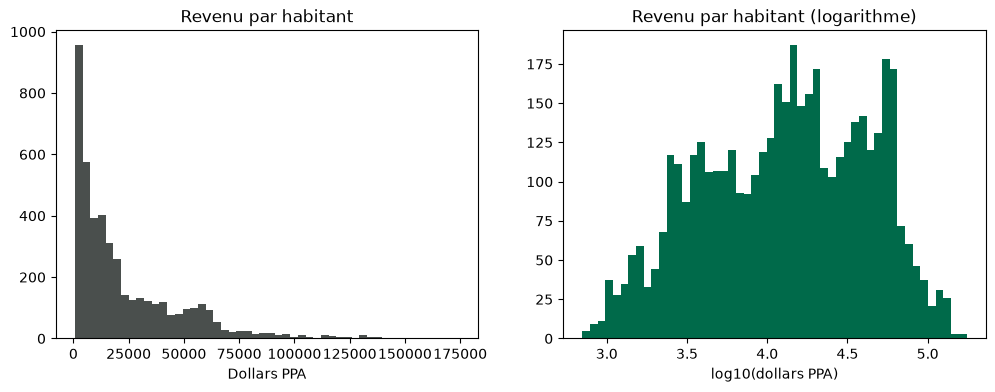

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(donnees["pib_par_habitant"].dropna(), bins=50, color="#4A4F4D")
axes[0].set_title("Revenu par habitant")
axes[0].set_xlabel("Dollars PPA")
axes[1].hist(np.log10(donnees["pib_par_habitant"].dropna()), bins=50, color="#006A4A")
axes[1].set_title("Revenu par habitant (logarithme)")
axes[1].set_xlabel("log10(dollars PPA)")
plt.show()

À gauche, la plupart des pays sont écrasés à gauche et quelques pays très riches étirent l'axe. Avec le logarithme, un passage de 1 000 à 10 000 dollars compte autant qu'un passage de 10 000 à 100 000 : c'est plus proche de l'effet réel du revenu sur la santé.

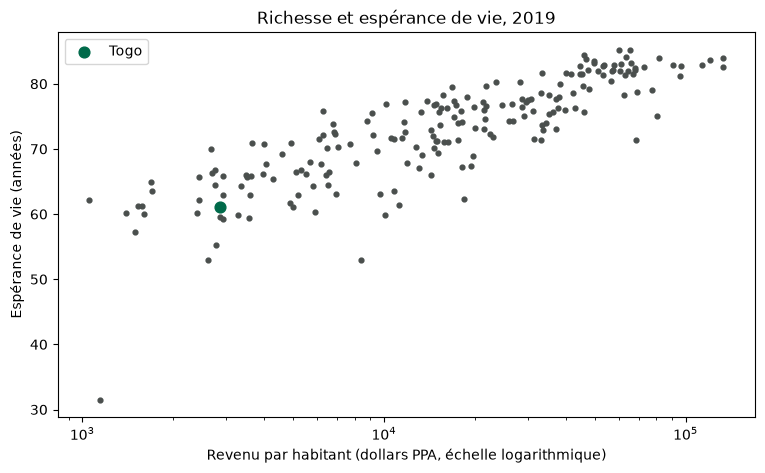

In [8]:
annee_2019 = donnees[donnees["annee"] == 2019]

plt.figure(figsize=(9, 5))
plt.scatter(annee_2019["pib_par_habitant"], annee_2019["esperance_vie"], s=12, color="#4A4F4D")
togo = annee_2019[annee_2019["pays"] == "Togo"]
plt.scatter(togo["pib_par_habitant"], togo["esperance_vie"], s=60, color="#006A4A", label="Togo")
plt.xscale("log")
plt.xlabel("Revenu par habitant (dollars PPA, échelle logarithmique)")
plt.ylabel("Espérance de vie (années)")
plt.title("Richesse et espérance de vie, 2019")
plt.legend()
plt.show()

## Étape 6 · Les valeurs aberrantes

**La règle des quartiles (ou règle de Tukey)**, la plus utilisée pour repérer des valeurs aberrantes :
- Q1 = la valeur sous laquelle se trouvent 25 % des observations ; Q3 = celle sous laquelle se trouvent 75 % ;
- l'écart interquartile vaut Q3 − Q1 ;
- une valeur est dite **aberrante** si elle est en dessous de Q1 − 1,5 × écart ou au-dessus de Q3 + 1,5 × écart.

Attention : *aberrant* veut dire *inhabituel*, pas forcément *faux*. Chaque valeur repérée se discute avec la connaissance du terrain.

In [9]:
q1 = donnees["esperance_vie"].quantile(0.25)
q3 = donnees["esperance_vie"].quantile(0.75)
limite_basse = q1 - 1.5 * (q3 - q1)
print("Limite basse de la règle des quartiles :", round(limite_basse, 1), "ans")

donnees[donnees["esperance_vie"] < limite_basse][["pays", "annee", "esperance_vie", "pib_par_habitant"]]

Limite basse de la règle des quartiles : 47.2 ans


,pays,annee,esperance_vie,pib_par_habitant
115,Angola,2000,46.501,6794.530211
116,Angola,2001,47.032,6846.792695
851,Central African Republic,2000,46.609,1245.813996
852,Central African Republic,2001,46.734,1272.857108
853,Central African Republic,2002,46.840,1290.383149
860,Central African Republic,2009,14.665,1402.681648
861,Central African Republic,2010,46.871,1479.413678
865,Central African Republic,2014,40.265,1001.855981
868,Central African Republic,2017,45.231,1103.866093
870,Central African Republic,2019,31.530,1145.095637


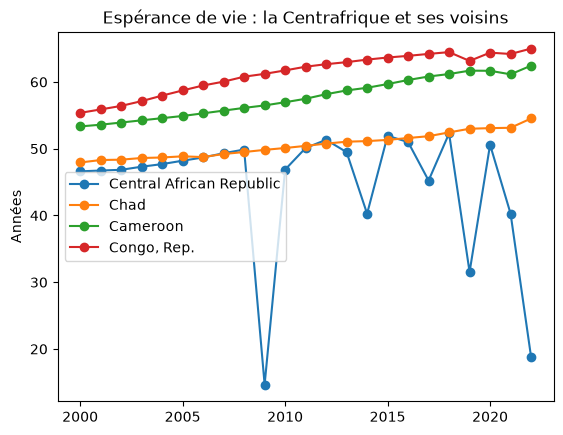

In [10]:
# La République centrafricaine et ses voisins, année par année
for pays in ["Central African Republic", "Chad", "Cameroon", "Congo, Rep."]:
    serie = donnees[donnees["pays"] == pays]
    plt.plot(serie["annee"], serie["esperance_vie"], marker="o", label=pays)
plt.title("Espérance de vie : la Centrafrique et ses voisins")
plt.ylabel("Années")
plt.legend()
plt.show()

**À discuter** : la courbe de la Centrafrique est en dents de scie (15 ans en 2009, 40 ans en 2014, 31 ans en 2019, 19 ans en 2022), alors que ses voisins progressent régulièrement. Des conflits peuvent faire baisser fortement l'espérance de vie, mais pas remonter de 20 ans l'année suivante : ces creux ressemblent plutôt à un **artefact des estimations** (ces chiffres sont modélisés par les Nations unies à partir de données incomplètes, pas mesurés).
**Décision** : on vérifierait à la source avant de conclure. Ici, on les garde, et on mesurera leur effet à l'étape 19.

## Étape 7 · Les corrélations

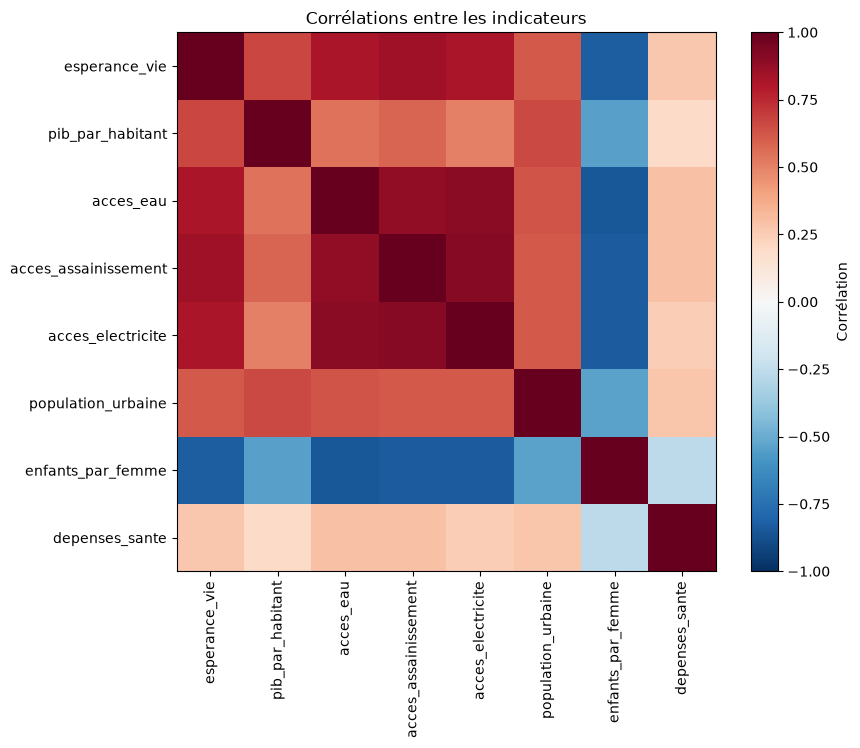

In [11]:
correlations = donnees[indicateurs].corr()      # corrélation entre chaque paire de colonnes (de -1 à 1)

plt.figure(figsize=(9, 7))
plt.imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1)    # rouge = varient ensemble, bleu = en sens contraire
plt.colorbar(label="Corrélation")
plt.xticks(range(len(correlations)), correlations.columns, rotation=90)
plt.yticks(range(len(correlations)), correlations.columns)
plt.title("Corrélations entre les indicateurs")
plt.show()

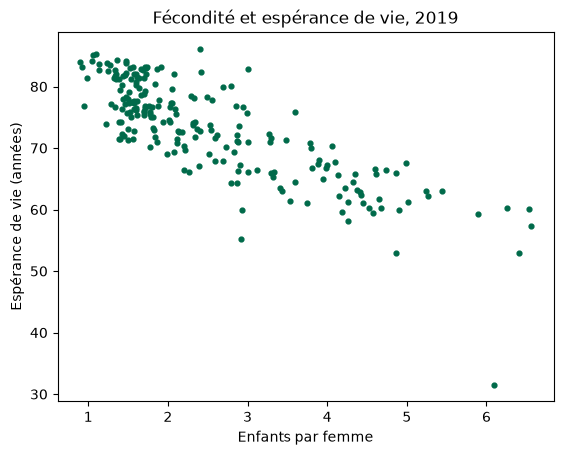

In [12]:
plt.scatter(annee_2019["enfants_par_femme"], annee_2019["esperance_vie"], s=12, color="#006A4A")
plt.xlabel("Enfants par femme")
plt.ylabel("Espérance de vie (années)")
plt.title("Fécondité et espérance de vie, 2019")
plt.show()

La fécondité est très liée à l'espérance de vie. Mais **corrélation n'est pas causalité** : les deux dépendent du développement en général (éducation des femmes, santé, revenu…).

## Étape 8 · L'Afrique de l'Ouest

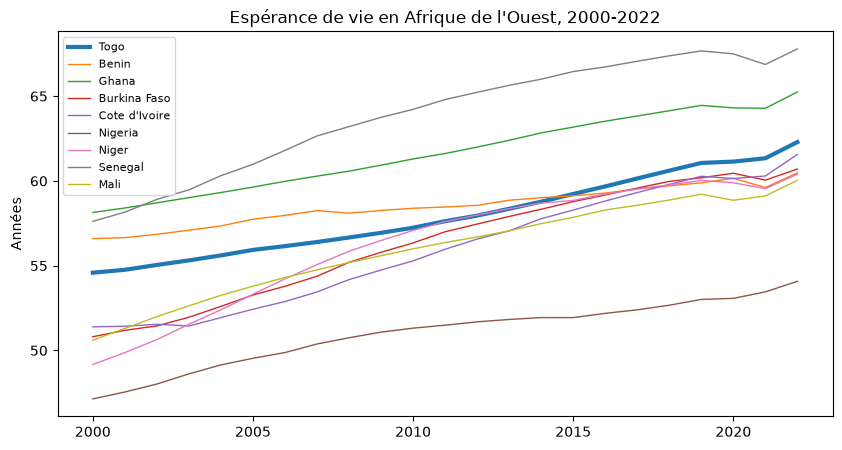

In [13]:
afrique_ouest = ["Togo", "Benin", "Ghana", "Burkina Faso", "Cote d'Ivoire", "Nigeria", "Niger", "Senegal", "Mali"]

plt.figure(figsize=(10, 5))
for pays in afrique_ouest:
    serie = donnees[donnees["pays"] == pays]
    plt.plot(serie["annee"], serie["esperance_vie"], label=pays, linewidth=3 if pays == "Togo" else 1)
plt.title("Espérance de vie en Afrique de l'Ouest, 2000-2022")
plt.ylabel("Années")
plt.legend(fontsize=8)
plt.show()

## Étape 9 · Les pays du monde par région

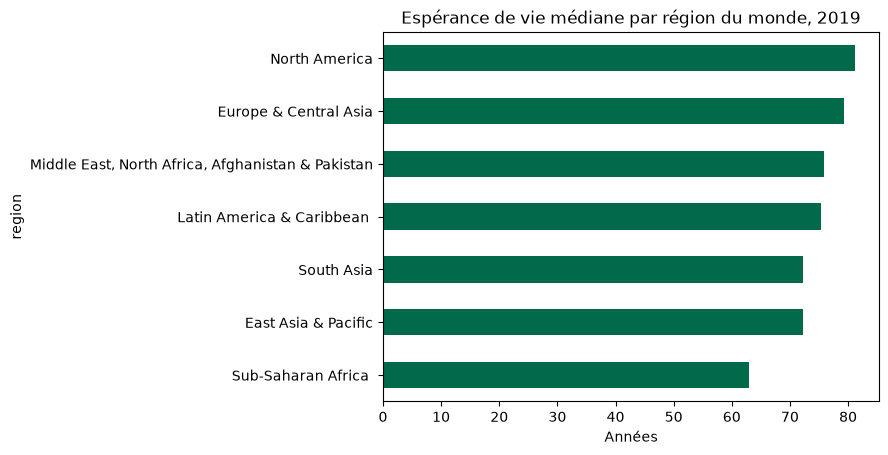

In [14]:
par_region = donnees[donnees["annee"] == 2019].groupby("region")["esperance_vie"].median().sort_values()
par_region.plot(kind="barh", color="#006A4A")
plt.title("Espérance de vie médiane par région du monde, 2019")
plt.xlabel("Années")
plt.show()

# Partie B · Construire les modèles

## Étape 10 · Préparer les données

In [15]:
# On garde les lignes où tous les indicateurs sont connus
propres = donnees.dropna(subset=indicateurs).copy()

# Le logarithme du revenu
propres["log_revenu"] = np.log(propres["pib_par_habitant"])

colonnes = ["log_revenu", "acces_eau", "acces_assainissement", "acces_electricite",
            "population_urbaine", "enfants_par_femme", "depenses_sante"]
print("Lignes conservées :", len(propres), "pour", propres["pays"].nunique(), "pays")

Lignes conservées : 4108 pour 185 pays


## Étape 11 · Séparer apprentissage et test… par pays

Un même pays apparaît chaque année. Si le Togo 2010 est dans l'apprentissage et le Togo 2011 dans le test, le modèle « reconnaît » le Togo au lieu d'apprendre. On met donc de côté **des pays entiers**.

In [16]:
separation = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=1)
lignes_apprentissage, lignes_test = next(separation.split(propres, groups=propres["pays"]))

apprentissage = propres.iloc[lignes_apprentissage]
test = propres.iloc[lignes_test].copy()

print("Pays pour apprendre :", apprentissage["pays"].nunique())
print("Pays pour tester :", test["pays"].nunique())

Pays pour apprendre : 138
Pays pour tester : 47


## Étape 12 · La référence : l'espérance de vie moyenne

Sans modèle, on prédirait la même valeur pour tous les pays : la moyenne de l'apprentissage.

In [17]:
moyenne = apprentissage["esperance_vie"].mean()
erreur_reference = mean_absolute_error(test["esperance_vie"], [moyenne] * len(test))
print("Erreur moyenne en prédisant toujours", round(moyenne, 1), "ans :", round(erreur_reference, 1), "ans")

Erreur moyenne en prédisant toujours 70.0 ans : 6.9 ans


## Étape 13 · Premier modèle : la régression linéaire

In [18]:
lineaire = LinearRegression()
lineaire.fit(apprentissage[colonnes], apprentissage["esperance_vie"])

test["prevision_lineaire"] = lineaire.predict(test[colonnes])
print("Erreur moyenne (régression linéaire) :", round(mean_absolute_error(test["esperance_vie"], test["prevision_lineaire"]), 1), "ans")

# Ce que la régression a appris
pd.Series(lineaire.coef_, index=colonnes).round(2)

Erreur moyenne (régression linéaire) : 3.3 ans


log_revenu              1.98
acces_eau               0.01
acces_assainissement    0.08
acces_electricite       0.01
population_urbaine      0.02
enfants_par_femme      -1.75
depenses_sante          0.17
dtype: float64

**Lire les poids** : −1,75 pour `enfants_par_femme` signifie qu'un enfant de plus par femme va avec 1,75 année d'espérance de vie en moins, les autres indicateurs étant égaux. Une association, pas un effet causal.

## Étape 14 · Modèle d'IA : la forêt aléatoire

In [19]:
foret = RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1)
foret.fit(apprentissage[colonnes], apprentissage["esperance_vie"])

test["prevision_foret"] = foret.predict(test[colonnes])
print("Erreur moyenne (forêt aléatoire) :", round(mean_absolute_error(test["esperance_vie"], test["prevision_foret"]), 1), "ans")

Erreur moyenne (forêt aléatoire) : 3.3 ans


# Partie C · Analyser les résultats

## Étape 15 · Le piège : séparer au hasard

In [20]:
apprentissage_hasard, test_hasard = train_test_split(propres, test_size=0.25, random_state=1)

foret_hasard = RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1)
foret_hasard.fit(apprentissage_hasard[colonnes], apprentissage_hasard["esperance_vie"])

erreur_hasard = mean_absolute_error(test_hasard["esperance_vie"], foret_hasard.predict(test_hasard[colonnes]))
print("Erreur moyenne avec une séparation au hasard :", round(erreur_hasard, 1), "ans")

Erreur moyenne avec une séparation au hasard : 0.9 ans


L'erreur paraît bien plus faible… mais c'est une illusion : le modèle a vu les autres années des mêmes pays. **La bonne erreur est celle de l'étape 14.**

## Étape 16 · Prévu et observé

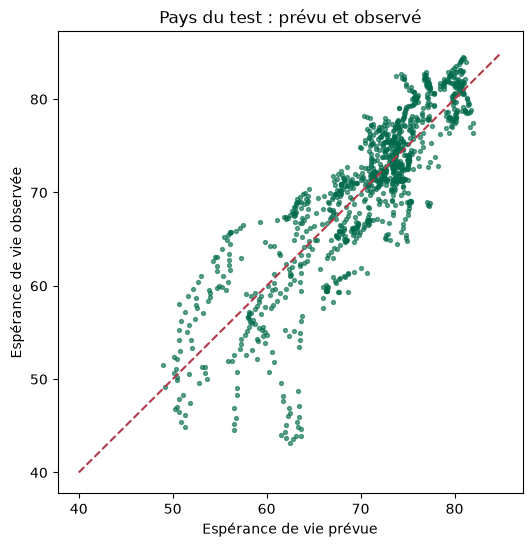

In [21]:
plt.figure(figsize=(6, 6))
plt.scatter(test["prevision_foret"], test["esperance_vie"], s=8, alpha=0.6, color="#006A4A")
plt.plot([40, 85], [40, 85], color="#B23A48", linestyle="--")
plt.xlabel("Espérance de vie prévue")
plt.ylabel("Espérance de vie observée")
plt.title("Pays du test : prévu et observé")
plt.show()

## Étape 17 · Les résidus par région

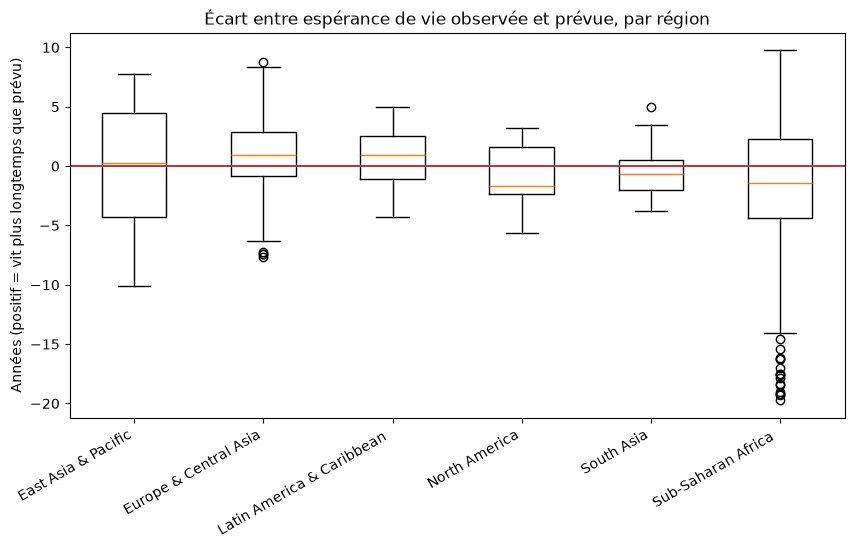

In [22]:
test["residu"] = test["esperance_vie"] - test["prevision_foret"]     # positif : le pays vit plus longtemps que prévu

regions = sorted(test["region"].unique())
plt.figure(figsize=(10, 5))
plt.boxplot([test[test["region"] == r]["residu"] for r in regions])
plt.xticks(range(1, len(regions) + 1), regions, rotation=30, ha="right")
plt.axhline(0, color="#B23A48")
plt.title("Écart entre espérance de vie observée et prévue, par région")
plt.ylabel("Années (positif = vit plus longtemps que prévu)")
plt.show()

## Étape 18 · Les pays au-dessus et en dessous des attentes

In [23]:
ecart_par_pays = test.groupby("pays")["residu"].mean().sort_values()

print("Pays qui vivent MOINS longtemps que leurs indicateurs ne le laissent attendre :")
print(ecart_par_pays.head(5).round(1))
print()
print("Pays qui vivent PLUS longtemps que leurs indicateurs ne le laissent attendre :")
print(ecart_par_pays.tail(5).round(1))

Pays qui vivent MOINS longtemps que leurs indicateurs ne le laissent attendre :
pays
Lesotho              -13.2
Eswatini             -10.7
Palau                 -7.7
Naoero                -7.3
Russian Federation    -4.6
Name: residu, dtype: float64

Pays qui vivent PLUS longtemps que leurs indicateurs ne le laissent attendre :
pays
Angola             4.4
China              4.4
Solomon Islands    5.3
Ireland            5.5
Mauritania         7.3
Name: residu, dtype: float64


**À discuter** : ces écarts sont des pistes de recherche. Conflits, épidémies (VIH, Ebola), qualité du système de santé, alimentation… ce que les indicateurs ne mesurent pas.

## Étape 19 · L'effet des valeurs aberrantes

In [24]:
sans_aberrantes = propres[propres["esperance_vie"] >= limite_basse]
print("Lignes retirées :", len(propres) - len(sans_aberrantes))

scores_avec = cross_val_score(RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1), propres[colonnes], propres["esperance_vie"],
                              groups=propres["pays"], cv=GroupKFold(n_splits=5), scoring="neg_mean_absolute_error")
scores_sans = cross_val_score(RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1), sans_aberrantes[colonnes], sans_aberrantes["esperance_vie"],
                              groups=sans_aberrantes["pays"], cv=GroupKFold(n_splits=5), scoring="neg_mean_absolute_error")
print("Erreur moyenne avec les valeurs aberrantes :", round(-scores_avec.mean(), 2), "ans")
print("Erreur moyenne sans les valeurs aberrantes :", round(-scores_sans.mean(), 2), "ans")

Lignes retirées : 40


Erreur moyenne avec les valeurs aberrantes : 2.84 ans
Erreur moyenne sans les valeurs aberrantes : 2.66 ans


## Étape 20 · La stabilité : validation croisée par pays

`GroupKFold` découpe les pays en 5 groupes et teste tour à tour sur chacun.

In [25]:
print("Forêt, erreur sur chacun des 5 groupes de pays :", (-scores_avec).round(2), "ans")

scores_lineaire = cross_val_score(LinearRegression(), propres[colonnes], propres["esperance_vie"],
                                  groups=propres["pays"], cv=GroupKFold(n_splits=5), scoring="neg_mean_absolute_error")
print("Régression linéaire :", (-scores_lineaire).round(2), "ans → moyenne", round(-scores_lineaire.mean(), 2))

Forêt, erreur sur chacun des 5 groupes de pays : [3.49 3.32 2.74 2.27 2.39] ans
Régression linéaire : [3.02 3.44 3.2  2.74 2.54] ans → moyenne 2.99


# Partie D · Utiliser et conclure

## Étape 21 · Ce qui compte pour la forêt

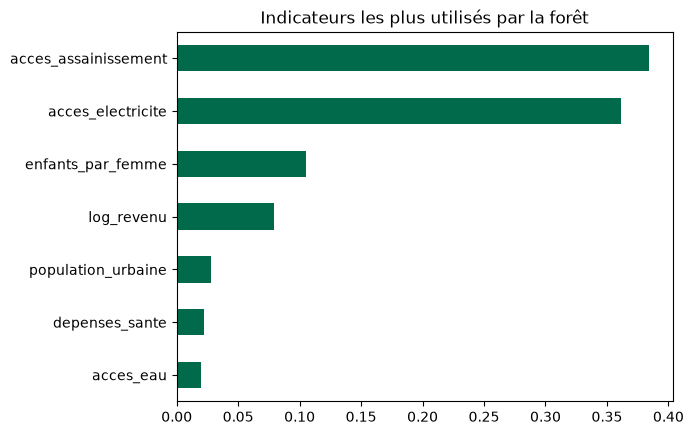

In [26]:
pd.Series(foret.feature_importances_, index=colonnes).sort_values().plot(kind="barh", color="#006A4A")
plt.title("Indicateurs les plus utilisés par la forêt")
plt.show()

## Étape 22 · Le prototype appliqué au Togo

On entraîne un modèle sans le Togo, puis on lui demande de prédire l'espérance de vie du Togo année par année.

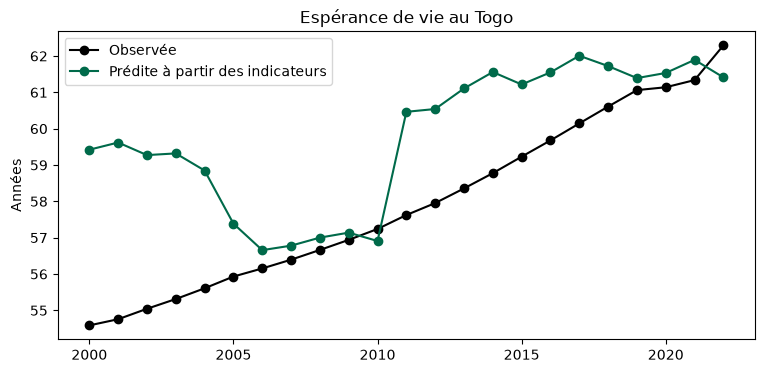

In [27]:
sans_togo = propres[propres["pays"] != "Togo"]
togo = propres[propres["pays"] == "Togo"]

foret_togo = RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1)
foret_togo.fit(sans_togo[colonnes], sans_togo["esperance_vie"])

plt.figure(figsize=(9, 4))
plt.plot(togo["annee"], togo["esperance_vie"], "o-", color="black", label="Observée")
plt.plot(togo["annee"], foret_togo.predict(togo[colonnes]), "o-", color="#006A4A", label="Prédite à partir des indicateurs")
plt.ylabel("Années")
plt.title("Espérance de vie au Togo")
plt.legend()
plt.show()

L'écart entre les deux courbes est une question de recherche : le Togo vit-il plus ou moins longtemps que ses indicateurs ne le laissent attendre, et pourquoi ?